# Black-Scholes PIKAN Implementation

In this notebook, I implement a Physics-Informed Kolmogorov-Arnold Network (PIKAN) to approximate the solution of the Black-Scholes PDE for a European call option.

The aim is to train a neural network to learn the option price $V(S,\tau)$, where:

- $S$ is the stock price
- $\tau$ is the time to maturity
- $V(S,\tau)$ is the option value

As in the PINN notebook, I use the transformation

$$
\tau = T - t,
$$

so the Black-Scholes PDE is written in forward time-to-maturity form as

$$
\frac{\partial V}{\partial \tau}
=
\frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2}
+ rS \frac{\partial V}{\partial S}
- rV.
$$

The PIKAN takes the input pair $(S,\tau)$ and outputs an approximation to the option price $V(S,\tau)$.

Unlike the standard PINN, which uses a multilayer perceptron with fixed activation functions, the PIKAN uses a Kolmogorov-Arnold Network style architecture. This replaces standard neural network layers with learnable univariate function representations, giving the model a different approximation structure..

The model is trained by minimizing a loss function made up of four terms:

1. PDE loss: measures how well the network satisfies the Black-Scholes PDE inside the domain.
2. Lower boundary loss: enforces the option price at the lower stock price boundary.
3. Upper boundary loss: enforces the option price at the upper stock price boundary.
4. Initial payoff loss: enforces the European call payoff at $\tau = 0$.

For a European call option, the payoff condition is

$$
V(S,0) = \max(S-K,0).
$$

The boundary conditions used are

$$
V(0,\tau) = 0,
$$

and

$$
V(S_{\max},\tau) = S_{\max} - Ke^{-r\tau}.
$$

The fixed parameter set used in this notebook is:

- Strike price: $K = 100$
- Maturity: $T = 1$
- Risk-free rate: $r = 0.05$
- Volatility: $\sigma = 0.2$
- Upper stock price boundary: $S_{\max} = 3K$

Once the PIKAN is trained, I compare its predicted option prices against the analytical Black-Scholes solution. I then use the same error metrics as in the PINN notebook so that the PIKAN, PINN, and Crank-Nicolson methods can be compared consistently.

In [2]:
import sys
sys.path.append("..")

import torch
import numpy as np
import matplotlib.pyplot as plt
import gc
from src.metrics import error_summary
import pandas as pd

torch.set_num_threads(1)

from src.analytical import black_scholes_call_grid
from src.pikan import BlackScholesPIKAN
from src.training_points import generate_training_points
from src.losses import black_scholes_pde_loss
from src.metrics import error_summary

torch.manual_seed(42)
np.random.seed(42)


In [4]:
# Defining parameters. Note I am using the same parameters as in the PINN notebook for consistency.

K = 100  # Strike price
T = 1.0  # Time to maturity
r = 0.05  # Risk-free interest rate
sigma = 0.2  # Volatility
S_max = 3*K # Maximum stock price considered

In [5]:
# Training the PIKAN model.

model_pikan = BlackScholesPIKAN(
    layers=[2, 16, 16, 1],
    grid=5,
    degree=3,
    S_max=S_max,
    T=T,
    seed=42
)

model_pikan.train()

optimizer = torch.optim.Adam(model_pikan.parameters(), lr=1e-3)

loss_history = []

epochs = 3000

N_f = 300
N_ic = 150
N_bc = 150

def train_step():
    training_data = generate_training_points(
        N_f=N_f,
        N_ic=N_ic,
        N_bc=N_bc,
        S_max=S_max,
        T=T,
        K=K,
        r=r
    )

    optimizer.zero_grad(set_to_none=True)

    total_loss, loss_pde, loss_ic, loss_lb, loss_ub = black_scholes_pde_loss(
        model_pikan,
        training_data,
        r=r,
        sigma=sigma,
        K=K
    )

    total_loss.backward()
    optimizer.step()

    values = (
        total_loss.detach().item(),
        loss_pde.detach().item(),
        loss_ic.detach().item(),
        loss_lb.detach().item(),
        loss_ub.detach().item()
    )

    return values


for epoch in range(epochs):
    total, pde, ic, lb, ub = train_step()

    loss_history.append(total)

    if epoch % 100 == 0:
        gc.collect()

    if epoch % 500 == 0:
        print(
            f"Epoch {epoch}: "
            f"Total={total:.6e}, "
            f"PDE={pde:.6e}, "
            f"IC={ic:.6e}, "
            f"LB={lb:.6e}, "
            f"UB={ub:.6e}"
        )

Epoch 0: Total=5.092773e+00, PDE=9.262727e-08, IC=9.937017e-01, LB=3.771991e-08, UB=4.099071e+00
Epoch 500: Total=1.500672e-01, PDE=5.215966e-03, IC=7.265426e-03, LB=2.996876e-06, UB=1.375828e-01
Epoch 1000: Total=1.505434e-04, PDE=9.265407e-05, IC=3.471211e-05, LB=3.845535e-07, UB=2.279271e-05
Epoch 1500: Total=4.160508e-05, PDE=2.797901e-05, IC=1.026977e-05, LB=2.143801e-08, UB=3.334859e-06
Epoch 2000: Total=2.110333e-05, PDE=1.239429e-05, IC=8.113359e-06, LB=1.319321e-08, UB=5.824874e-07
Epoch 2500: Total=1.560309e-05, PDE=6.782084e-06, IC=8.545543e-06, LB=8.279105e-09, UB=2.671871e-07


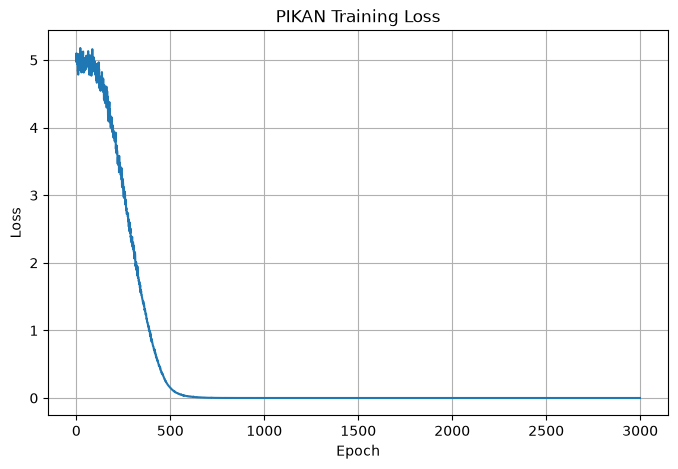

In [6]:
# Plotting the loss.

plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PIKAN Training Loss")
plt.grid()
plt.show()

In [7]:
# Create evaluation grid
S_eval = torch.linspace(0, S_max, 100)
tau_eval = torch.linspace(0, T, 50)

S_grid, tau_grid = torch.meshgrid(S_eval, tau_eval, indexing="ij")

S_flat = S_grid.reshape(-1, 1)
tau_flat = tau_grid.reshape(-1, 1)

# Evaluate PIKAN on the full grid
model_pikan.eval()
with torch.no_grad():
    V_pred = model_pikan(S_flat, tau_flat)

V_surface_pikan = V_pred.reshape(S_grid.shape).detach().numpy()
S_grid_np = S_grid.numpy()
tau_grid_np = tau_grid.numpy()

# Comparing PIKAN predictions with the exact Black-Scholes solution
V_exact_surface = black_scholes_call_grid(S_grid_np,tau_grid_np,K,r,sigma)
abs_error_surface_pikan = np.abs(V_surface_pikan - V_exact_surface)

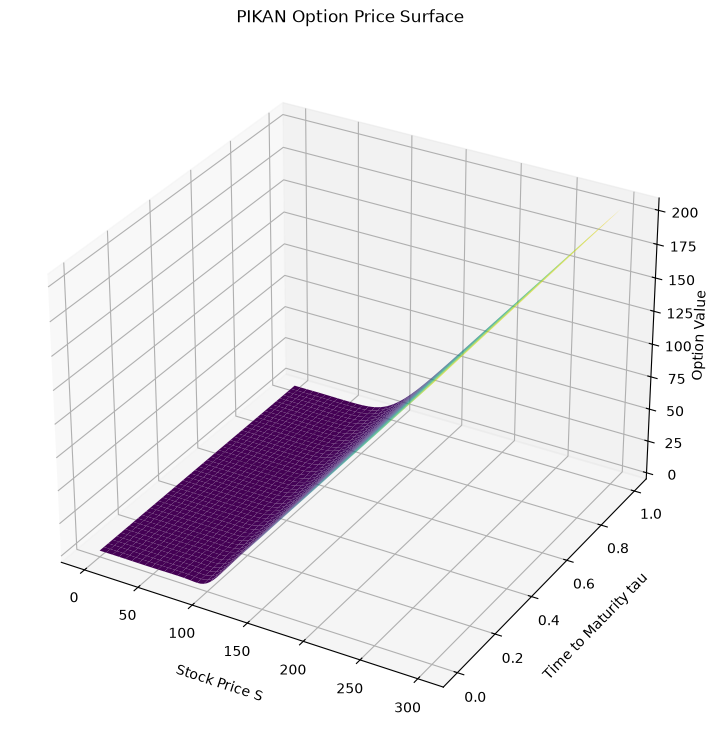

In [8]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(S_grid_np, tau_grid_np, V_surface_pikan, cmap="viridis")

ax.set_title("PIKAN Option Price Surface", pad=20)
ax.set_xlabel("Stock Price S", labelpad=10)
ax.set_ylabel("Time to Maturity tau", labelpad=10)
ax.set_zlabel("Option Value", labelpad=0)

fig.subplots_adjust(left=0.02, right=0.78, top=0.9, bottom=0.05)

plt.show()

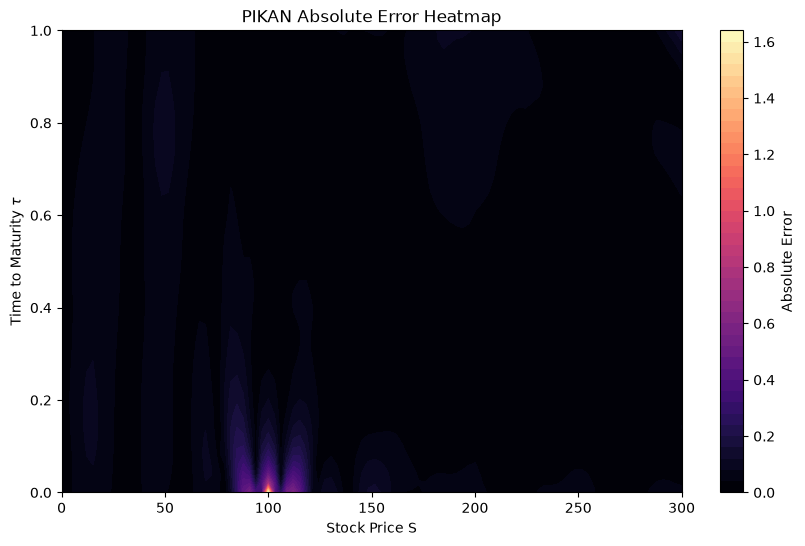

In [9]:
# Now, plot the absolute error heatmap between the PIKAN predictions and the analytical solution.
# Plotting a heatmap as it provides a clear visual representation of the error distribution across the grid of stock prices and times to maturity.

plt.figure(figsize=(10, 6))

plt.contourf(S_grid_np, tau_grid_np, abs_error_surface_pikan, levels=50, cmap="magma")
plt.colorbar(label="Absolute Error")

plt.title("PIKAN Absolute Error Heatmap")
plt.xlabel("Stock Price S")
plt.ylabel("Time to Maturity $\\tau$")

plt.show()

In [10]:
# Plotting some key metrics for a more quantitative assessment of the PIKAN's performance against the analytical solution.

metrics = error_summary(V_surface_pikan, V_exact_surface)

metrics_table = pd.DataFrame({
    "Metric": metrics.keys(),
    "Value": metrics.values()
})

metrics_table

,Metric,Value
0,MSE,0.003373
1,RMSE,0.058075
2,MAE,0.033826
3,Max Abs Error,1.629618
4,Relative L2 Error,0.000601


In [11]:
# Defining a function that counts the number of trainable parameters in a given model architecture.
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

count_parameters(model_pikan)

4256

## PIKAN tuning

The PIKAN performs well but with a long runtime. Note that according to the loss curve it doesn't seem as if 3000 epochs is necessary. I will run one more experiment with 1000 epochs, as this seems to be around where the loss curve settles.

In [12]:
# Training the PIKAN model with fewer epochs.

model_pikan_short = BlackScholesPIKAN(
    layers=[2, 16, 16, 1],
    grid=5,
    degree=3,
    S_max=S_max,
    T=T,
    seed=42
)

model_pikan_short.train()

optimizer = torch.optim.Adam(model_pikan_short.parameters(), lr=1e-3)

loss_history = []

epochs = 1000

N_f = 300
N_ic = 150
N_bc = 150

def train_step():
    training_data = generate_training_points(
        N_f=N_f,
        N_ic=N_ic,
        N_bc=N_bc,
        S_max=S_max,
        T=T,
        K=K,
        r=r
    )

    optimizer.zero_grad(set_to_none=True)

    total_loss, loss_pde, loss_ic, loss_lb, loss_ub = black_scholes_pde_loss(
        model_pikan_short,
        training_data,
        r=r,
        sigma=sigma,
        K=K
    )

    total_loss.backward()
    optimizer.step()

    values = (
        total_loss.detach().item(),
        loss_pde.detach().item(),
        loss_ic.detach().item(),
        loss_lb.detach().item(),
        loss_ub.detach().item()
    )

    return values


for epoch in range(epochs):
    total, pde, ic, lb, ub = train_step()

    loss_history.append(total)

    if epoch % 100 == 0:
        gc.collect()

    if epoch % 500 == 0:
        print(
            f"Epoch {epoch}: "
            f"Total={total:.6e}, "
            f"PDE={pde:.6e}, "
            f"IC={ic:.6e}, "
            f"LB={lb:.6e}, "
            f"UB={ub:.6e}"
        )

Epoch 0: Total=5.092773e+00, PDE=9.262727e-08, IC=9.937017e-01, LB=3.771991e-08, UB=4.099071e+00
Epoch 500: Total=1.500672e-01, PDE=5.215966e-03, IC=7.265426e-03, LB=2.996876e-06, UB=1.375828e-01


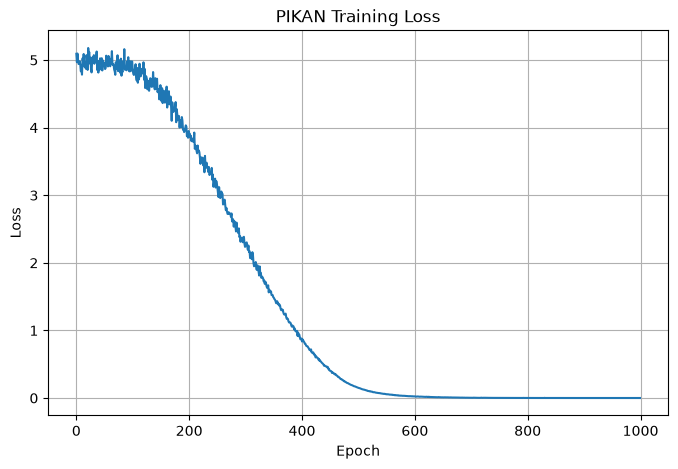

In [13]:
# Plotting the loss.

plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PIKAN Training Loss")
plt.grid()
plt.show()

In [14]:
# Create evaluation grid
S_eval = torch.linspace(0, S_max, 100)
tau_eval = torch.linspace(0, T, 50)

S_grid, tau_grid = torch.meshgrid(S_eval, tau_eval, indexing="ij")

S_flat = S_grid.reshape(-1, 1)
tau_flat = tau_grid.reshape(-1, 1)

# Evaluate PIKAN on the full grid
model_pikan_short.eval()
with torch.no_grad():
    V_pred = model_pikan_short(S_flat, tau_flat)

V_surface_pikan_short = V_pred.reshape(S_grid.shape).detach().numpy()
S_grid_np = S_grid.numpy()
tau_grid_np = tau_grid.numpy()

# Comparing PIKAN predictions with the exact Black-Scholes solution
abs_error_surface_pikan_short = np.abs(V_surface_pikan_short - V_exact_surface)

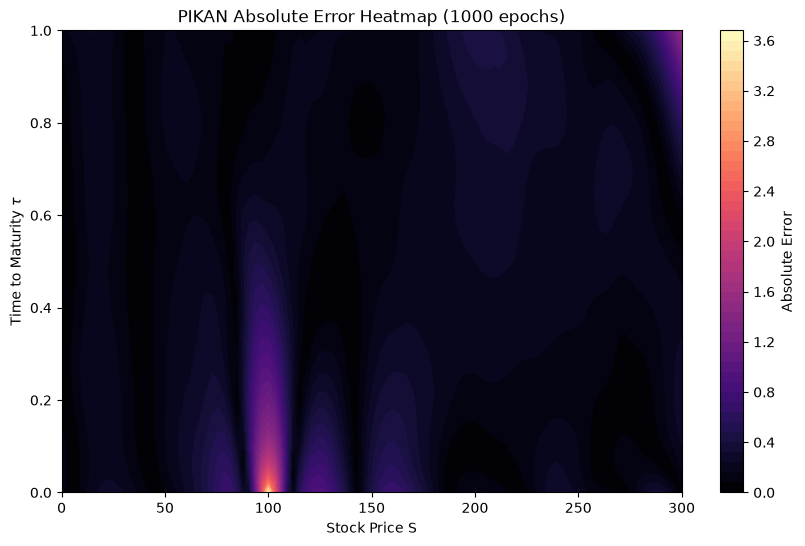

In [15]:
# Now, plot the absolute error heatmap between the PIKAN (with fewer epochs) predictions and the analytical solution.
# Plotting a heatmap as it provides a clear visual representation of the error distribution across the grid of stock prices and times to maturity.

plt.figure(figsize=(10, 6))

plt.contourf(S_grid_np, tau_grid_np, abs_error_surface_pikan_short, levels=50, cmap="magma")
plt.colorbar(label="Absolute Error")

plt.title("PIKAN Absolute Error Heatmap (1000 epochs)")
plt.xlabel("Stock Price S")
plt.ylabel("Time to Maturity $\\tau$")

plt.show()

In [16]:
# Plotting some key metrics for a more quantitative assessment of the PIKAN's performance against the analytical solution.

metrics = error_summary(V_surface_pikan_short, V_exact_surface)

metrics_table = pd.DataFrame({
    "Metric": metrics.keys(),
    "Value": metrics.values()
})

metrics_table

,Metric,Value
0,MSE,0.082062
1,RMSE,0.286464
2,MAE,0.204735
3,Max Abs Error,3.646942
4,Relative L2 Error,0.002964


In [19]:
# Comparing the short-trained PIKAN and regular PIKAN models.

pikan_short_metrics = error_summary(V_surface_pikan_short, V_exact_surface)
pikan_metrics = error_summary(V_surface_pikan, V_exact_surface)

pikan_comparison_rows = [
    {
        "Method": "PIKAN (1000 epochs)",
        "Architecture / Grid": "[2, 16, 16, 1], grid=5, degree=3",
        "Trainable Parameters": sum(p.numel() for p in model_pikan_short.parameters() if p.requires_grad),
        "Epochs": 1000,
        "Training Points": "N_f=300, N_ic=150, N_bc=150",
        "Runtime (s)": 88.1,
        "Runtime per Epoch (s)": 0.0081,
        "MSE": pikan_short_metrics["MSE"],
        "RMSE": pikan_short_metrics["RMSE"],
        "MAE": pikan_short_metrics["MAE"],
        "Max Abs Error": pikan_short_metrics["Max Abs Error"],
        "Relative L2 Error": pikan_short_metrics["Relative L2 Error"],
    },
    {
        "Method": "PIKAN",
        "Architecture / Grid": "[2, 16, 16, 1], grid=5, degree=3",
        "Trainable Parameters": sum(p.numel() for p in model_pikan.parameters() if p.requires_grad),
        "Epochs": 3000,
        "Training Points": "N_f=300, N_ic=150, N_bc=150",
        "Runtime (s)": 257.6,
        "Runtime per Epoch (s)": 0.085867,
        "MSE": pikan_metrics["MSE"],
        "RMSE": pikan_metrics["RMSE"],
        "MAE": pikan_metrics["MAE"],
        "Max Abs Error": pikan_metrics["Max Abs Error"],
        "Relative L2 Error": pikan_metrics["Relative L2 Error"],
    }
]

pikan_comparison_table = pd.DataFrame(pikan_comparison_rows)

pikan_comparison_table

,Method,Architecture / Grid,Trainable Parameters,Epochs,Training Points,Runtime (s),Runtime per Epoch (s),MSE,RMSE,MAE,Max Abs Error,Relative L2 Error
0,PIKAN (1000 epochs),"[2, 16, 16, 1], grid=5, degree=3",4256,1000,"N_f=300, N_ic=150, N_bc=150",88.1,0.008100,0.082062,0.286464,0.204735,3.646942,0.002964
1,PIKAN,"[2, 16, 16, 1], grid=5, degree=3",4256,3000,"N_f=300, N_ic=150, N_bc=150",257.6,0.085867,0.003373,0.058075,0.033826,1.629618,0.000601


In [20]:
# Saving the PIKAN comparison table.

from pathlib import Path

tables_dir = Path("../results/tables")
tables_dir.mkdir(parents=True, exist_ok=True)

pikan_comparison_table_save = pikan_comparison_table.copy()

pikan_comparison_table_save = pikan_comparison_table_save.round({
    "Runtime (s)": 2,
    "Runtime per Epoch (s)": 5,
    "MSE": 6,
    "RMSE": 6,
    "MAE": 6,
    "Max Abs Error": 6,
    "Relative L2 Error": 6
})

pikan_comparison_table_save.to_csv(
    tables_dir / "pikan_comparison.csv",
    index=False
)

The relative error here as well as the maximum absolute error is higher that the original PIKAN trained with 3000 epochs. This indicates that the loss curve might not tell the full story.

Despite the higher errors than the model trained on 3000 epochs, I will also use this model in the final comparison as it achieved better errors than even the best PINN model with only a slightly longer runtime.